<a href="https://colab.research.google.com/github/Gizeh-Gutierrez/Maestria_programacion/blob/main/Sesion12_Evaluacion_Analisis_Descriptivo_271752.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evaluación — Análisis Descriptivo de Datos

**Entrega individual**

- **Nombre:** Gizeh Gutierrez
- **Matrícula:** 271752

Esta evaluación aplica los cuatro bloques de la Sesión 12 (tendencia central, dispersión, forma, visualización) a un dataset que no se trabajó en clase: **NYC Airbnb 2019**, específicamente la columna `price`.

| | |
|---|---|
| **Tiempo estimado** | 45-55 min |
| **Entrega** | Notebook completo (.ipynb) con todas las celdas ejecutadas, subido a Moodle |
| **Puntaje total** | 100 puntos (ver rúbrica al final) |

Cada actividad tiene su propia pregunta de conclusión — esas respuestas se califican como parte de la actividad correspondiente, no concentradas en la reflexión final. Comenta tu código donde tomes una decisión (por ejemplo, cuántos bins usar en un histograma, o qué columna comparar) — el comentario también forma parte del puntaje.

## Preparación

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = 'https://raw.githubusercontent.com/pjournal/boun01g-data-mine-r-s/gh-pages/Assignment/AB_NYC_2019.csv'
df = pd.read_csv(url)
df[['name', 'neighbourhood_group', 'room_type', 'price']].head()

,name,neighbourhood_group,room_type,price
0,Clean & quiet apt home by the park,Brooklyn,Private room,149
1,Skylit Midtown Castle,Manhattan,Entire home/apt,225
2,THE VILLAGE OF HARLEM....NEW YORK !,Manhattan,Private room,150
3,Cozy Entire Floor of Brownstone,Brooklyn,Entire home/apt,89
4,Entire Apt: Spacious Studio/Loft by central park,Manhattan,Entire home/apt,80


---
## Actividad 1 — Tendencia central (20 pts)

In [2]:
# 1.1 — Calcula la media, mediana y moda de la columna 'price'.


media = df['price'].mean()
mediana = df['price'].median()
moda = df['price'].mode()[0]  # mode() devuelve una serie; tomamos el primer valor

print(f"Media: {media:.2f}")
print(f"Mediana: {mediana:.2f}")
print(f"Moda: {moda}")


Media: 152.72
Mediana: 106.00
Moda: 100


**1.2 — Conclusión (responde aquí en Markdown):**

¿La media y la mediana de `price` se parecen o divergen mucho? Con base en lo que viste en clase sobre `Income`, ¿qué te sugiere esa divergencia (o esa similitud) sobre la presencia de valores extremos en esta columna?

_Tu respuesta:_ La media 152.72 es mucho mayor que la mediana 106.00, lo que indica la presencia de valores extremos altos. Esto sugiere que la distribución de price está sesgada hacia la derecha y que la mediana representa mejor el precio típico de los alojamientos.

---
## Actividad 2 — Dispersión (20 pts)

In [3]:
# 2.1 — Calcula el rango, la varianza, la desviación estándar y el IQR (Q1, Q3, IQR) de 'price'.

rango = df['price'].max() - df['price'].min()
varianza = df['price'].var()
desviacion = df['price'].std()

Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

print(f"Rango: {rango:.2f}")
print(f"Varianza: {varianza:.2f}")
print(f"Desviación estándar: {desviacion:.2f}")
print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")


Rango: 10000.00
Varianza: 57674.03
Desviación estándar: 240.15
Q1: 69.00
Q3: 175.00
IQR: 106.00


**2.2 — Conclusión (responde aquí en Markdown):**

Compara el rango contra el IQR de `price`. ¿Cuál de los dos te parece más representativo de la dispersión "típica" de los precios, y por qué? (revisa el valor máximo de la columna antes de responder)

_Tu respuesta:_ El IQR 106 es más representativo de la dispersión típica de los precios que el rango 10,000. Esto se debe a que el rango está  influenciado por el valor máximo de la columna, que es muy alto en comparación con la mayoría de los anuncios. En cambio, el IQR mide la dispersión del 50% central de los datos y no se ve afectado por esos valores extremos, por lo que describe mejor la variabilidad habitual de los precios.

---
## Actividad 3 — Forma (20 pts)

In [12]:
# 3.1 — Calcula la asimetría (skew) y la curtosis (kurt) de 'price'.

asimetria = df['price'].skew()
curtosis = df['price'].kurt()

print(f"Asimetría: {asimetria:.2f}")
print(f"Curtosis: {curtosis:.2f}")


Asimetría: 19.12
Curtosis: 585.67


**3.2 — Conclusión (responde aquí en Markdown):**

Compara estos valores con los de `Income` que viste en clase (asimetría 6.76, curtosis 159.6 con el outlier incluido). ¿Cómo se comparan los de `price`? ¿Qué relación esperarías entre estos valores y lo que vas a encontrar en la próxima etapa del curso (Datos Atípicos)?

_Tu respuesta:_ Los valores de price asimetría = 19.12, curtosis = 585.67 son mucho mayores que los de Income asimetría = 6.76, curtosis = 159.6. Esto indica que la distribución de precios está aún más sesgada hacia la derecha y contiene una mayor cantidad de valores extremos.

Se esperaria que se identifiquen numerosos outliers, especialmente precios excepcionalmente altos que influyen fuertemente en la media, la dispersión y la forma de la distribución.

---
## Actividad 4 — Visualización (30 pts)

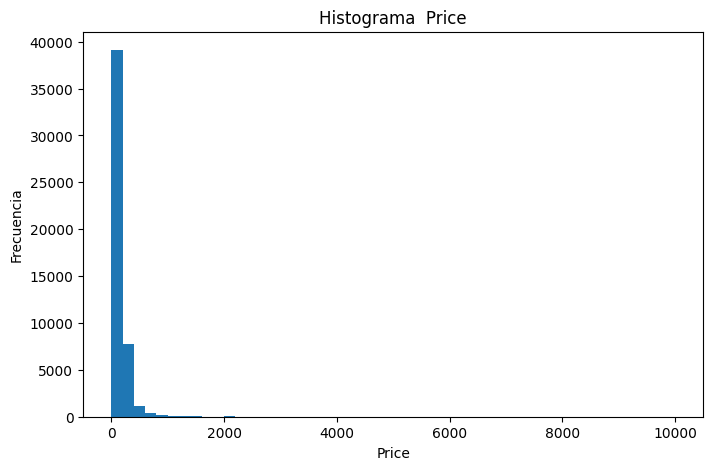

In [11]:
# 4.1 — Construye un histograma de 'price' con .plot(kind='hist').
# Elige un número de bins que te parezca razonable y comenta por qué lo elegiste.

df['price'].plot(kind='hist', bins=50, figsize=(8,5))
plt.title('Histograma  Price')
plt.xlabel('Price')
plt.ylabel('Frecuencia')
plt.show()



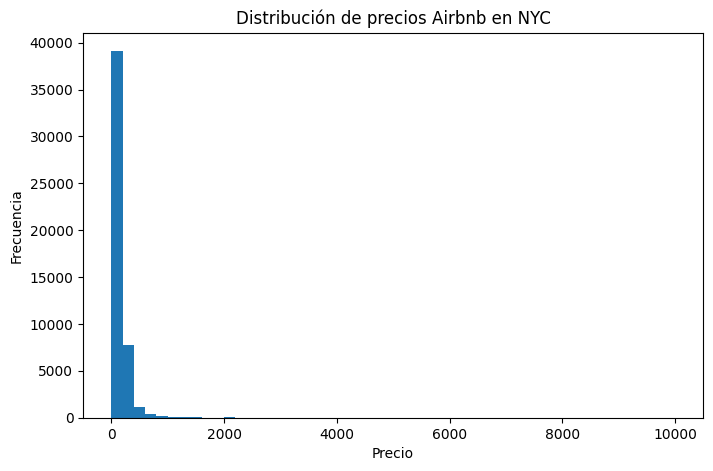

In [10]:
# 4.2 — Construye el mismo histograma con matplotlib.pyplot directamente (plt.hist()),
# agregando título y etiquetas en los ejes.

plt.figure(figsize=(8,5))
plt.hist(df['price'], bins=50)
plt.title('Distribución de precios Airbnb en NYC')
plt.xlabel('Precio')
plt.ylabel('Frecuencia')
plt.show()



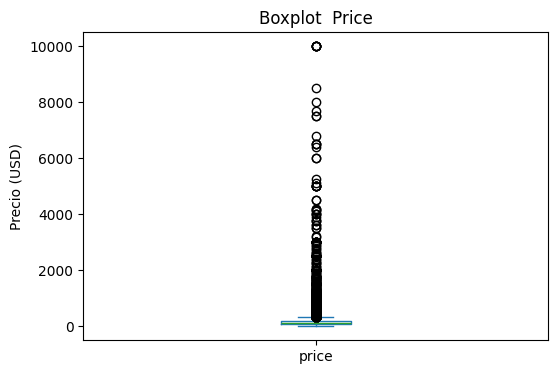

In [9]:
# 4.3 — Construye un boxplot de 'price' (con .plot(kind='box') o plt.boxplot()).

df['price'].plot(kind='box', figsize=(6,4))
plt.title('Boxplot  Price')
plt.ylabel('Precio (USD)')
plt.show()



**4.4 — Conclusión (responde aquí en Markdown):**

Describe lo que observas en el histograma y el boxplot de `price`. ¿Los outliers son visibles en ambos gráficos? ¿En cuál se distinguen mejor? Relaciona tu respuesta con los valores de asimetría y curtosis que calculaste en la Actividad 3.

_Tu respuesta:_El histograma muestra que la mayoría de los alojamientos tienen precios bajos o moderados, mientras que existe una cola muy larga hacia la derecha formada por unos pocos precios extremadamente altos. El boxplot confirma esta situación al mostrar numerosos puntos fuera del rango típico de los datos.

Los outliers son visibles en ambos gráficos, pero se distinguen mejor en el boxplot, ya que aparecen claramente separados de la caja y los bigotes. En el histograma, los valores extremos son visibles principalmente por la larga cola derecha.

Estos resultados coinciden con la asimetría positiva muy alta 19.12 y la curtosis extremadamente elevada 585.67, que indican una distribución fuertemente sesgada y con una gran cantidad de valores atípicos extremos.

---
## Reflexión final (10 pts)

Con base en las 4 actividades anteriores: si tuvieras que explicarle a alguien que no ha visto este dataset por qué el precio "promedio" de $152.72 puede ser engañoso, ¿qué le dirías, usando al menos dos de las medidas que calculaste?

_Tu respuesta:_El precio promedio de 152.72 puede ser engañoso porque está influenciado por unos pocos alojamientos con precios extremadamente altos. Esto se observa al comparar la media 152.72 con la mediana 106.00, que representa mejor el precio típico de los anuncios. Además, el rango de 10,000 y la asimetría de 19.12 muestran que existen valores extremos muy alejados de la mayoría de los precios. Por ello, aunque el promedio sea 152.72, la mayoría de los alojamientos tienen precios considerablemente más bajos.

---
## Rúbrica de evaluación

| Actividad | Puntos | Criterio |
|---|---|---|
| 1. Tendencia central | 20 | Calcula correctamente media, mediana, moda; la conclusión (1.2) conecta la divergencia con la presencia de outliers, no es una afirmación aislada |
| 2. Dispersión | 20 | Calcula correctamente rango, varianza, std, IQR; la conclusión (2.2) justifica cuál medida es más representativa con evidencia del propio cálculo |
| 3. Forma | 20 | Calcula correctamente asimetría y curtosis; la conclusión (3.2) compara explícitamente contra el caso de `Income` visto en clase |
| 4. Visualización | 30 | Histograma y boxplot correctamente construidos (ambas versiones: `.plot()` y `plt.`); código comentado justificando decisiones (ej. bins); la conclusión (4.4) conecta lo visual con los estadísticos de la Actividad 3 |
| Reflexión final | 10 | La explicación usa al menos dos medidas concretas, no es una respuesta genérica |
| **Total** | **100** | |